# Quickstart: predictive maintenance on real heavy-vehicle data

Five minutes, no dataset download. This notebook reads the versioned results in `reports/`, shows the headline numbers of the
four datasets, and scores three real SCANIA trucks from `examples/` with the published model (the same one the FastAPI
service and the Docker image serve).

In [1]:
import json, os
from pathlib import Path
if Path.cwd().name == "notebooks":
    os.chdir("..")
import pandas as pd
from IPython.display import Image, display
pd.set_option("display.width", 140)

## 1. Headline results (read from `reports/*/results.json`)

In [2]:
sc = json.loads(Path("reports/scania/results.json").read_text(encoding="utf-8"))
aps = json.loads(Path("reports/aps/results.json").read_text(encoding="utf-8"))
cm = json.loads(Path("reports/cmapss/results.json").read_text(encoding="utf-8"))
mp = json.loads(Path("reports/metropt/results.json").read_text(encoding="utf-8"))
sel = sc["seleccionado"]
ae = mp["detectors"]["autoencoder__absolute"]
pd.DataFrame([
    {"dataset": "SCANIA Component X", "selected (no test)": sel,
     "test result": f"{sc['modelos'][sel]['test']['ahorro_pct']:.1f}% lower official cost {sc['modelos'][sel]['test']['ahorro_ic95']}"},
    {"dataset": "APS Failure", "selected (no test)": aps["selected_by_oof"],
     "test result": f"cost {aps['models'][aps['selected_by_oof']]['test']['cost']:,} (IDA 2016 winner: 9,920)"},
    {"dataset": "NASA C-MAPSS", "selected (no test)": ", ".join(d["selected_by_cv"] for d in cm["subsets"].values()),
     "test result": "RMSE " + " / ".join(f"{d['selected_test']['rmse']:.1f}" for d in cm["subsets"].values())},
    {"dataset": "MetroPT-3", "selected (no test)": "autoencoder (5 detectors reported)",
     "test result": f"{ae['detected_2h']}/4 leaks, {ae['chance_detected_2h']:.1f} by chance, {ae['false_alarms_per_week']:.1f} false alarms/week"},
])

,dataset,selected (no test),test result
0,SCANIA Component X,ensemble,"29.1% lower official cost [18.61, 37.62]"
1,APS Failure,ensemble,"cost 9,150 (IDA 2016 winner: 9,920)"
2,NASA C-MAPSS,"gru, ensemble, gru, ensemble",RMSE 15.4 / 27.4 / 13.7 / 28.9
3,MetroPT-3,autoencoder (5 detectors reported),"4/4 leaks, 2.0 by chance, 7.9 false alarms/week"


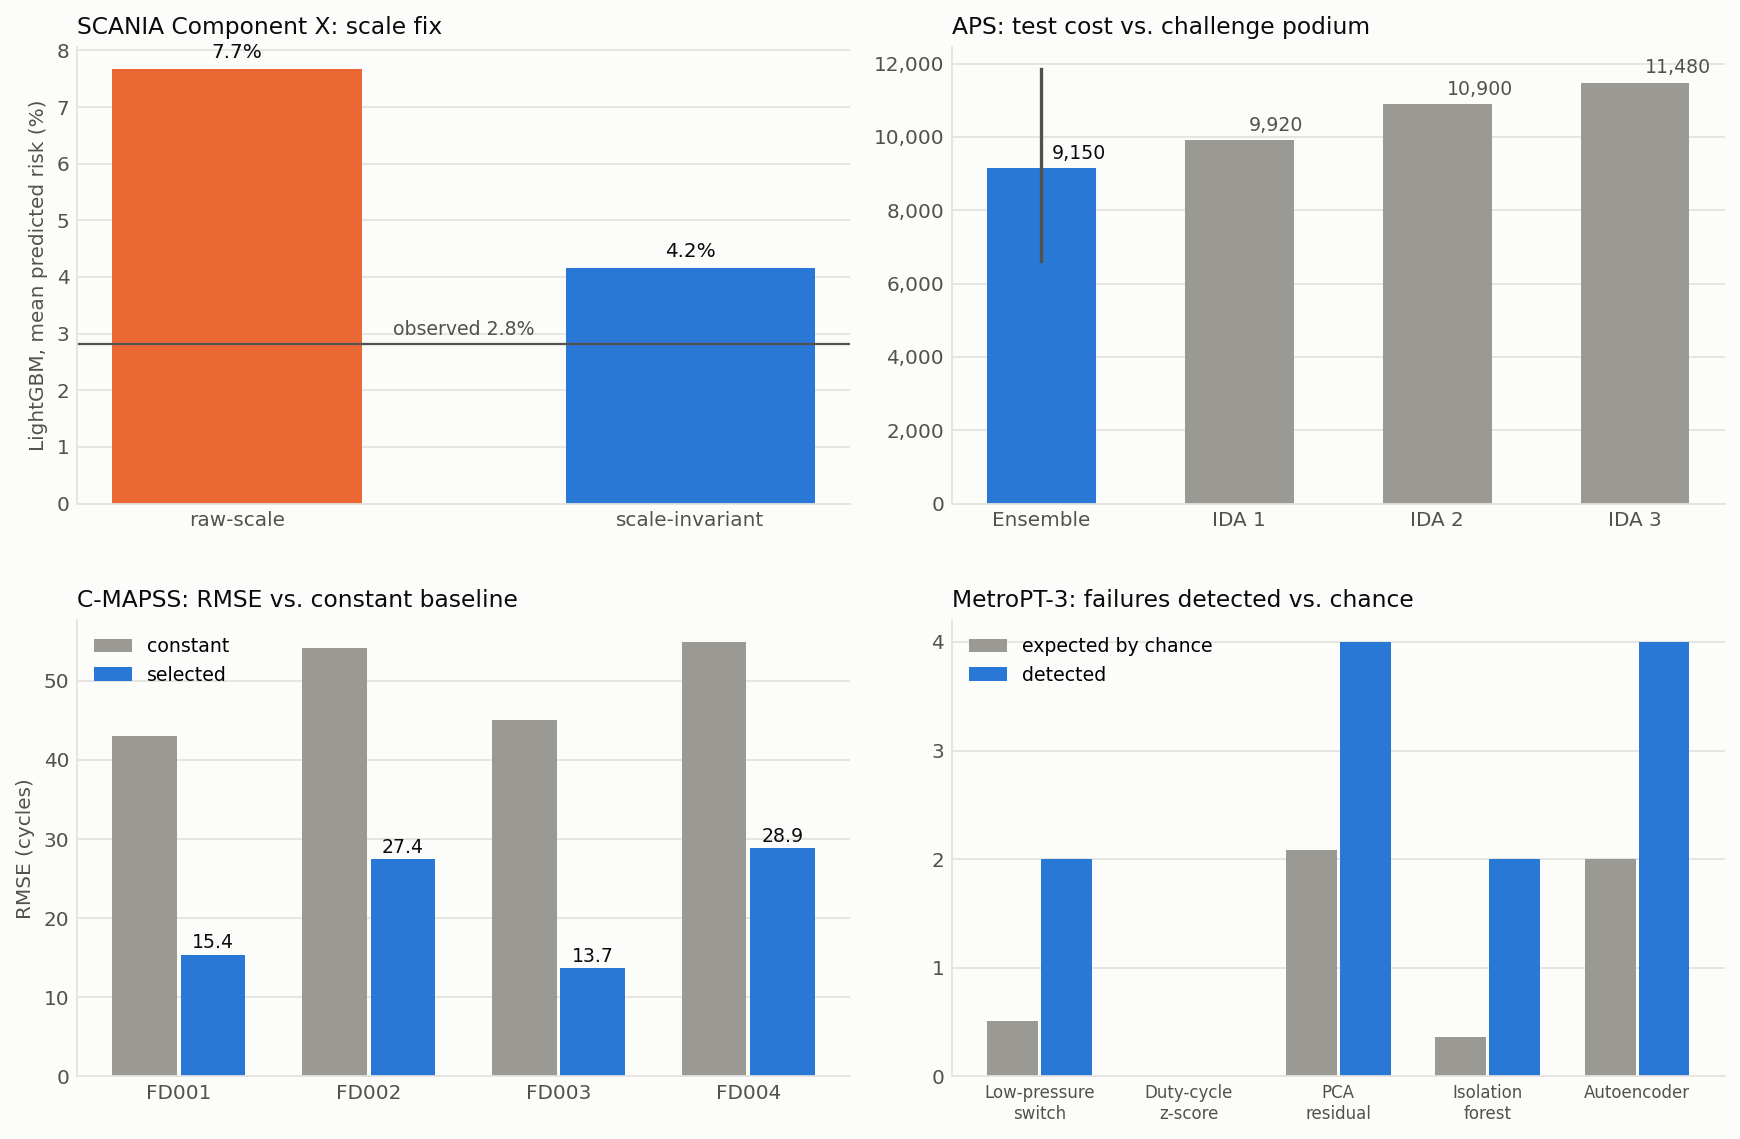

In [3]:
display(Image("reports/figures/en/overview.png", width=900))

## 2. The hidden scale shift in SCANIA Component X

Every anonymised variable is multiplied by a different factor in train, validation and test. A classifier trained to tell the
splits apart (adversarial validation) separates them perfectly on raw-scale features and much less on scale-invariant ones.

In [4]:
pd.DataFrame({k: {p: v["auc"] for p, v in d.items()} for k, d in sc["escala"]["validacion_adversarial"].items()})

,todas,invariantes
train_vs_validation,1.0,0.82
train_vs_test,1.0,0.81
validation_vs_test,1.0,0.67


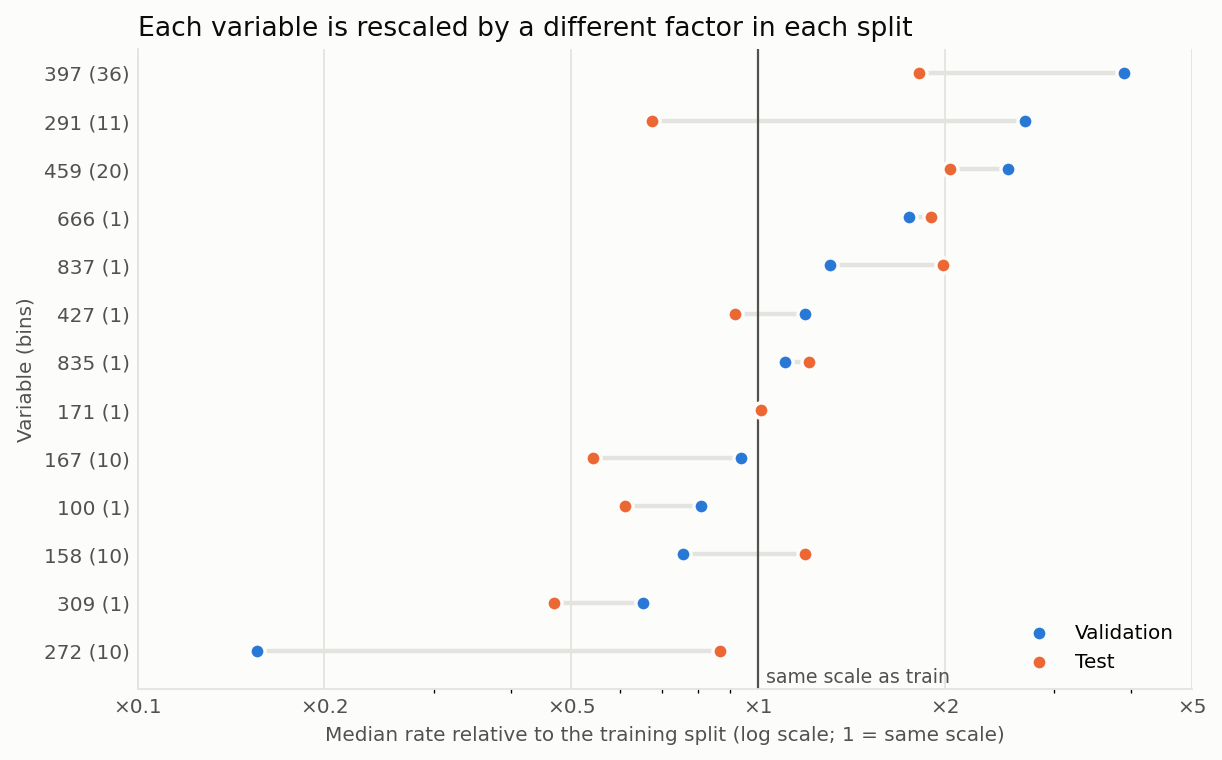

In [5]:
display(Image("reports/figures/en/scania_scale_shift.png", width=800))

## 3. Score real trucks with the published model

In [6]:
from src.demo import MODELS_DIR, fetch_model, score_examples
if not (MODELS_DIR / "risk_classifier.joblib").exists():
    fetch_model()
pd.DataFrame(score_examples())

,file,true_class,readouts,any_risk,recommended,action
0,truck_10_class0.json,0,102,0.013321,0,Sin accion: operacion normal.
1,truck_1285_class3.json,3,109,0.061162,4,Retirar de operacion y revisar ahora (falla pr...
2,truck_189_class4.json,4,61,0.040776,3,Revision urgente (falla probable en 6-12 unida...
3,truck_3309_class4.json,4,32,0.010555,0,Sin accion: operacion normal.


`true_class` is what really happened (0 = no repair within 48 time units, 4 = repair within 6). The recommendation is the
action of minimum expected cost under the challenge's cost matrix, not the most probable class.

## 4. What if a workshop visit costs more?

The saving depends on the cost of an unnecessary visit (7–10 in the challenge). Recomputing the decision for the selected model
on the 10,091 validation and test trucks, with no retraining:

In [7]:
from src.models import calibration as K
pred = pd.read_csv("reports/scania/predictions.csv")
rows = []
for k in (0.5, 1, 2, 3, 5, 10):
    row = {"visit cost (x challenge)": k}
    for split in ("validation", "test"):
        d = pred[pred.split == split]
        row[split] = round(K.saving_at(d.class_label.to_numpy(), d[[f"p{i}" for i in range(5)]].to_numpy(), k)["ahorro_pct"], 1)
    rows.append(row)
pd.DataFrame(rows).set_index("visit cost (x challenge)")

,validation,test
visit cost (x challenge),,
0.5,60.2,52.4
1.0,41.7,29.1
2.0,13.4,12.0
3.0,11.4,6.0
5.0,4.9,-0.4
10.0,-2.4,-4.7


## 5. Serve it

```bash
docker build -t truck-risk .
docker run -p 8000:8000 -e RISK_API_KEY=change-me truck-risk
curl -s -X POST localhost:8000/score -H "X-API-Key: change-me" -H "Content-Type: application/json" \
     --data @examples/truck_189_class4.json
```

Everything else (four datasets, model comparisons, analysis) is in the [README](../README.md).